# Task 2

## Importe

In [20]:
import base_net as bn
import profiles as pr
from profiles import Lastprofil, Month, DayType, Season
import pandapower as pp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In die Datei `base_net.py` wurden folgende Funktionen ausgelagert:

- `build_base_net()`: erzeugt das Ausgangsnetz (Baseline) und gibt das Netz sowie die Indizes aller Elemente (`idx`) zurück. So startet jeder Test von einem frischen, identischen Netz.
- `vary_parameter(bauteil, parameter, werte, ausgaben)`: ändert einen Parameter eines Bauteils nacheinander auf alle angegebenen Werte, rechnet für jeden Wert einen Lastfluss auf einer frischen Netzkopie, prüft die Konvergenz und gibt die gewünschten Ergebnisse als Tabelle zurück. Der Ausgangswert (Baseline) wird automatisch mitgerechnet und markiert.
- `profiles.py`: liest die BDEW-Standardlastprofile ein (`load_profiles`), erzeugt daraus repräsentative Wochen je Monat (`build_week`, 5 × Werktag, 1 × Samstag, 1 × Sonntag/Feiertag) und stellt sie grafisch dar (`plot_week`, `plot_day`, `plot_seasons`, `plot_compare`). Profile, Monate, Tagtypen und Jahreszeiten werden über Enums angesprochen (`Lastprofil.HAUSHALT`, `Month.JULY`, `DayType.WT`, `Season.SUMMER`).

## Daten laden

Die BDEW-Standardlastprofile (Veröffentlichung 2025) liegen im Ordner `data/`:

| Enum | Datei | Inhalt |
|---|---|---|
| `Lastprofil.HAUSHALT` | `BDEW_H25_Haushalte.csv` | H25 – Haushaltskunden |
| `Lastprofil.PV` | `BDEW_P25_PV.csv` | P25 – Kombinationsprofil Haushalt mit PV-Anlage (Netzbezug) |

Die Dateien enthalten je Monat und Tagtyp (WT, SA, FT) 96 Viertelstundenwerte in kWh, normiert auf 1 Mio. kWh Jahresverbrauch. Sie werden hier einmal eingelesen und stehen danach im Dictionary `PROFILES` zur Verfügung.

**Hinweis zu P25:** Das Profil beschreibt den **Netzbezug** von Haushalten mit eigener PV-Anlage, nicht die PV-Erzeugung. Alle Werte sind positiv, mittags sinkt der Bezug, weil ein Teil des Verbrauchs aus der eigenen Anlage gedeckt wird. Eine Einspeisung ins Netz ist darin nicht enthalten.

In [21]:
PROFILES = pr.load_profiles("data")

for profil, df in PROFILES.items():
    print(f"{profil.label}: {df.shape[0]} Viertelstunden × {df.shape[1]} Spalten (Monat, Tagtyp)")

H25 – Haushalt: 96 Viertelstunden × 36 Spalten (Monat, Tagtyp)
P25 – Haushalt mit PV-Anlage (Netzbezug): 96 Viertelstunden × 36 Spalten (Monat, Tagtyp)


## Aufgabe 1

### Aufgabe von Trennschaltern

Kommt noch

### Netzwerk
Externes Netz → Bus 1 (20 kV) → Transformator → Bus 2 (0,4 kV) → Switch → Kabel → Switch → Bus 3 (0,4 kV) → Last

| Komponente | pandapower-Element | Wichtige Daten | Funktion |
|---|---|---|---|
| Externes Netz | `ext_grid` an Bus 1 | `vm_pu` = 1,02, Winkel 0° | Vorgelagertes Mittelspannungsnetz als starre Spannungsquelle. Es ist der Slack-Bus: Er gibt Spannung und Winkelreferenz vor und gleicht die Leistungsbilanz (Last + Verluste) aus. |
| Bus 1 | `bus`, 20 kV | Nennspannung 20 kV | Mittelspannungs-Sammelschiene, Oberspannungsseite des Trafos |
| Transformator | `trafo`, Typ „0.4 MVA 20/0.4 kV“ | S_r = 0,4 MVA, v_k = 6 %, v_kr = 1,425 %, Schaltgruppe Dyn5, Stufensteller ±2 × 2,5 % auf der OS-Seite | Ortsnetztransformator, setzt 20 kV auf 0,4 kV um |
| Bus 2 | `bus`, 0,4 kV | Nennspannung 0,4 kV | Niederspannungs-Sammelschiene der Ortsnetzstation |
| Switch Start | `switch_start` | Leistungsschalter | Leistungsschalter am Anfang des Kabels |
| Kabel | `line`, Typ „NAYY 4x50 SE“ | 0,1 km, r = 0,642 Ω/km, x = 0,083 Ω/km, c = 210 nF/km, I_max = 142 A, 1 System | Niederspannungs-Erdkabel (Aluminium, 50 mm²) zum Verbraucher |
| Switch End | `switch_end` | Leistungsschalter | Leistungsschalter am Ende des Kabels |
| Bus 3 | `bus`, 0,4 kV | Nennspannung 0,4 kV | Netzknoten am Ende des Kabels, Anschlusspunkt des Verbrauchers |
| Last | `load` an Bus 3 | P = 0,05 MW, Q = 0,005 Mvar | Verbraucher als Konstantleistungslast (ZIP-Anteile = 0) |

Das Netz aus Aufgabe 1 wurde volständig übernommen, neu ist nur, das am Anfang und am Ende der Leitung jeweils ein Leistungstrennschalter hinzugefügt wurde.

Beide wurden auf eien Kurzschlussspannung 142 A eingestellt, da dies der maximale Strom durch das Kabel ist.

### Datenstruktur

In [22]:
net, idx = bn.build_base_net()

In [23]:
net.bus

,name,vn_kv,type,zone,in_service,geo
0,Bus 1,20.0,b,None,True,None
1,Bus 2,0.4,b,None,True,None
2,Bus 3,0.4,b,None,True,None


In [24]:
net.trafo

,name,std_type,hv_bus,lv_bus,sn_mva,vn_hv_kv,vn_lv_kv,vk_percent,vkr_percent,pfe_kw,...,tap_step_degree,tap_pos,tap_changer_type,id_characteristic_table,tap_dependency_table,parallel,df,in_service,vector_group,oltc
0,Trafo,0.4 MVA 20/0.4 kV,0,1,0.4,20.0,0.4,6.0,1.425,1.35,...,0.0,0.0,Ratio,<NA>,False,1,1.0,True,Dyn5,False


In [25]:
net.line

,name,std_type,from_bus,to_bus,length_km,r_ohm_per_km,x_ohm_per_km,c_nf_per_km,g_us_per_km,max_i_ka,df,parallel,type,in_service,geo
0,Line,NAYY 4x50 SE,1,2,0.1,0.642,0.083,210.0,0.0,0.142,1.0,1,cs,True,None


In [26]:
net.load

,name,bus,p_mw,q_mvar,const_z_p_percent,const_i_p_percent,const_z_q_percent,const_i_q_percent,sn_mva,scaling,in_service,type
0,Load,2,0.05,0.005,0.0,0.0,0.0,0.0,NaN,1.0,True,wye


In [27]:
net.switch

,bus,element,et,type,closed,name,z_ohm,in_ka
0,1,0,l,CB,True,CB Line Start,0.0,0.142
1,2,0,l,CB,True,CB Line End,0.0,0.142


### Durchführung

In [28]:
pp.runpp(net)
net.res_bus

,vm_pu,va_degree,p_mw,q_mvar
0,1.020000,0.000000,-0.052513,-0.005511
1,1.017429,-150.405971,0.000000,0.000000
2,0.997047,-150.439166,0.050000,0.005000


In [29]:
net.res_line

,p_from_mw,q_from_mvar,p_to_mw,q_to_mvar,pl_mw,ql_mvar,i_from_ka,i_to_ka,i_ka,vm_from_pu,va_from_degree,vm_to_pu,va_to_degree,loading_percent
0,0.051019,0.005131,-0.05,-0.005,0.001019,0.000131,0.072743,0.072744,0.072744,1.017429,-150.405971,0.997047,-150.439166,51.227854


In [30]:
net.res_trafo

,p_hv_mw,q_hv_mvar,p_lv_mw,q_lv_mvar,pl_mw,ql_mvar,i_hv_ka,i_lv_ka,vm_hv_pu,va_hv_degree,vm_lv_pu,va_lv_degree,loading_percent
0,0.052513,0.005511,-0.051019,-0.005131,0.001494,0.00038,0.001494,0.072743,1.02,0.0,1.017429,-150.405971,12.941537


In [31]:
net.res_load

,p_mw,q_mvar
0,0.05,0.005


In [32]:
net.res_switch

,i_ka,loading_percent,p_from_mw,q_from_mvar,p_to_mw,q_to_mvar
0,0.072744,51.227854,NaN,NaN,NaN,NaN
1,0.072744,51.227854,NaN,NaN,NaN,NaN


#### Auswertung Baseline

| Größe | Wert |
|---|---|
| vm Bus 2 / Bus 3 | 1,0174 pu / 0,9970 pu |
| Spannungsfall Bus 2 → 3 | 0,0204 pu |
| Strom Leitung | 72,7 A |
| Auslastung Leitung / Trafo | 51,2 % / 12,9 % |
| Auslastung Switch Start / End | 51,2 % / 51,2 % |
| Verluste Leitung / Trafo | 1,02 kW / 1,49 kW |

Alle Werte liegen im zulässigen Bereich. Die Trafoverluste sind größer als die Leitungsverluste, weil bei geringer Auslastung die lastunabhängigen **Eisenverluste** (`pfe_kw` = 1,35 kW) dominieren.

## Aufgabe 2 – Transformator und Stufenschalter

### Theorie: Übersetzungsänderung

Ein Transformator überträgt die Spannung im Verhältnis seiner Windungszahlen. Die Übersetzung ist

ü = U_OS / U_US = N_OS / N_US.

Ein **Stufenschalter** verändert über Anzapfungen an einer Wicklung die wirksame Windungszahl und damit die Übersetzung in festen Stufen. Bei der Stufenstellung n und der Stufengröße s (in %) gilt für einen Stufenschalter auf der **Oberspannungsseite**:

ü(n) = ü_N · (1 + n · s/100)  ⇒  u_US ≈ u_OS / (1 + n · s/100)   (in pu, Leerlauf)

- Eine **positive** Stufe schaltet OS-Windungen zu, die Übersetzung wird größer und die US-Spannung **sinkt**.
- Eine **negative** Stufe hebt die US-Spannung an.

Sitzt der Stufenschalter auf der **Unterspannungsseite**, kehrt sich die Wirkrichtung um: ü(n) = ü_N / (1 + n · s/100), eine positive Stufe hebt dann die US-Spannung an. In Verteilnetztransformatoren liegt der Stufenschalter meist auf der OS-Seite, weil dort der Strom kleiner ist und die Anzapfungen leichter zugänglich sind.

**Regelbereich und Stufengröße:** Der Regelbereich ergibt sich aus der Zahl der Stufen und der Stufengröße, hier ±2 × 2,5 % = ±5 %. Kleine Stufen erlauben eine feinere Einstellung, große Stufen einen größeren Bereich bei gleicher Stufenzahl. Die Stufengröße bestimmt außerdem, wie breit das Totband eines Reglers mindestens sein muss, damit er nicht ständig hin- und herschaltet.

**Anzapfung ohne Last (Umsteller) vs. Laststufenschalter (OLTC):**

| | Umsteller / spannungslos verstellbar | Laststufenschalter (OLTC) |
|---|---|---|
| Umschalten | nur im freigeschalteten Zustand | unter Last, ohne Versorgungsunterbrechung |
| Aufbau | einfache Anzapfungen, manuell | Lastumschalter mit Übergangswiderständen oder -drosseln, Motorantrieb, Spannungsregler |
| Typischer Einsatz | klassischer Ortsnetztransformator, Anpassung bei Inbetriebnahme oder saisonal | HS/MS-Umspanntransformatoren, regelbare Ortsnetztransformatoren (rONT) |
| Schalthäufigkeit | selten (wenige Male pro Jahr) | häufig (automatische Regelung) |

*Quellen ergänzen: Fachbuch zu Transformatoren bzw. elektrischen Energieversorgungsnetzen mit Kapitel und Seiten.*

### Stufenschalter im Modell

Der Transformator vom Typ „0.4 MVA 20/0.4 kV“ besitzt in der pandapower-Standardbibliothek bereits einen Stufenschalter. Seine Parameter:

In [33]:
net, idx = bn.build_base_net()
tap_cols = ["tap_side", "tap_neutral", "tap_min", "tap_max", "tap_step_percent",
            "tap_step_degree", "tap_changer_type", "tap_pos", "oltc"]
net.trafo.loc[[idx["trafo"]], tap_cols].T

,0
tap_side,hv
tap_neutral,0.0
tap_min,-2.0
tap_max,2.0
tap_step_percent,2.5
tap_step_degree,0.0
tap_changer_type,Ratio
tap_pos,0.0
oltc,False


| Parameter | Wert | Einheit | Bedeutung |
|---|---|---|---|
| `tap_side` | hv | – | Regelseite: Oberspannungswicklung (20 kV) |
| `tap_neutral` | 0 | – | Neutralstellung, bei der die Nennübersetzung 20 kV / 0,4 kV gilt |
| `tap_min` / `tap_max` | −2 / +2 | – | zulässige Stufenpositionen (5 Stellungen) |
| `tap_step_percent` | 2,5 | % | Spannungsänderung je Stufe, bezogen auf die Bemessungsspannung der Regelseite |
| `tap_step_degree` | 0 | ° | keine Phasendrehung je Stufe |
| `tap_changer_type` | Ratio | – | Längsregler: ändert nur den Betrag der Übersetzung |
| `tap_pos` | 0 | – | aktuelle Stellung (Baseline: Neutralstellung) |
| `oltc` | False | – | **kein** Laststufenschalter: nur spannungslos verstellbar |

Daraus folgt ein **Regelbereich von ±5 %** (ü zwischen 0,95 · ü_N und 1,05 · ü_N). Das ist typisch für einen klassischen Ortsnetztransformator mit Umsteller. Die Parameter passen zum gewählten Gerät und werden daher nicht verändert.

Für die Untersuchung in Aufgabe 5 bedeutet `oltc = False`: Eine realistische Nachbildung ist eine **saisonal** angepasste, feste Stufenstellung. Eine Regelung im Viertelstundentakt setzt einen Laststufenschalter (rONT) voraus.

### Simulation: Variation der Tap-Position

Gegenüber der Baseline wird **nur** `tap_pos` geändert, und zwar auf alle zulässigen Stellungen von −2 bis +2. Jeder Rechenpunkt startet mit `vary_parameter()` von einem frischen Ausgangsnetz, die Konvergenz wird für jeden Fall geprüft.

Zusätzlich wird derselbe Durchlauf **im Leerlauf** (Last außer Betrieb) gerechnet. Dann fließt praktisch kein Strom, es gibt keinen Spannungsfall, und die Spannung an Bus 2 hängt nur von der Übersetzung ab. So lässt sich die Simulation direkt mit der Theorie vergleichen.

In [34]:
TAP_OUTPUTS = [
    ["res_bus.vm_pu.bus1",              "vm Bus 1 [pu]"],
    ["res_bus.vm_pu.bus2",              "vm Bus 2 [pu]"],
    ["res_bus.vm_pu.bus3",              "vm Bus 3 [pu]"],
    ["res_line.i_ka.line",              "I Leitung [kA]"],
    ["res_line.loading_percent.line",   "Auslastung Leitung [%]"],
    ["res_trafo.loading_percent.trafo", "Auslastung Trafo [%]"],
]
TAPS = [-2, -1, 1, 2]

# mit Last (Baseline-Betriebspunkt)
df_tap = bn.vary_parameter("trafo", "tap_pos", TAPS, TAP_OUTPUTS)
df_tap["I Leitung [A]"] = df_tap.pop("I Leitung [kA]") * 1000
df_tap["ΔU Bus 2→3 [pu]"] = df_tap["vm Bus 2 [pu]"] - df_tap["vm Bus 3 [pu]"]
df_tap

,trafo.tap_pos,Baseline,konvergiert,vm Bus 1 [pu],vm Bus 2 [pu],vm Bus 3 [pu],Auslastung Leitung [%],Auslastung Trafo [%],I Leitung [A],ΔU Bus 2→3 [pu]
0,-2.0,,True,1.02,1.071248,1.051929,48.555160,12.949737,68.948327,0.019319
1,-1.0,,True,1.02,1.043650,1.023801,49.889175,12.944707,70.842628,0.019850
2,0.0,x,True,1.02,1.017429,0.997047,51.227854,12.941537,72.743553,0.020382
3,1.0,,True,1.02,0.992483,0.971566,52.571358,12.940099,74.651329,0.020917
4,2.0,,True,1.02,0.968722,0.947268,53.919848,13.261627,76.566184,0.021453


In [35]:
def build_no_load_net():
    """Baseline, aber Last außer Betrieb (Leerlauf)."""
    net, idx = bn.build_base_net()
    net.load.at[idx["load"], "in_service"] = False
    return net, idx

df_tap_nl = bn.vary_parameter("trafo", "tap_pos", TAPS,
                              [["res_bus.vm_pu.bus2", "vm Bus 2 Leerlauf [pu]"]],
                              build_fn=build_no_load_net)

# Theorie: u_US = u_OS / (1 + n * s/100)
s = net.trafo.at[idx["trafo"], "tap_step_percent"]
u_os = net.ext_grid.at[idx["ext"], "vm_pu"]
df_tap_nl["Theorie [pu]"] = u_os / (1 + df_tap_nl["trafo.tap_pos"] * s / 100)
df_tap_nl["Abweichung [pu]"] = df_tap_nl["vm Bus 2 Leerlauf [pu]"] - df_tap_nl["Theorie [pu]"]
df_tap_nl

,trafo.tap_pos,Baseline,konvergiert,vm Bus 2 Leerlauf [pu],Theorie [pu],Abweichung [pu]
0,-2.0,,True,1.073659,1.073684,-0.000026
1,-1.0,,True,1.046129,1.046154,-0.000025
2,0.0,x,True,1.019976,1.020000,-0.000024
3,1.0,,True,0.995098,0.995122,-0.000024
4,2.0,,True,0.971405,0.971429,-0.000023


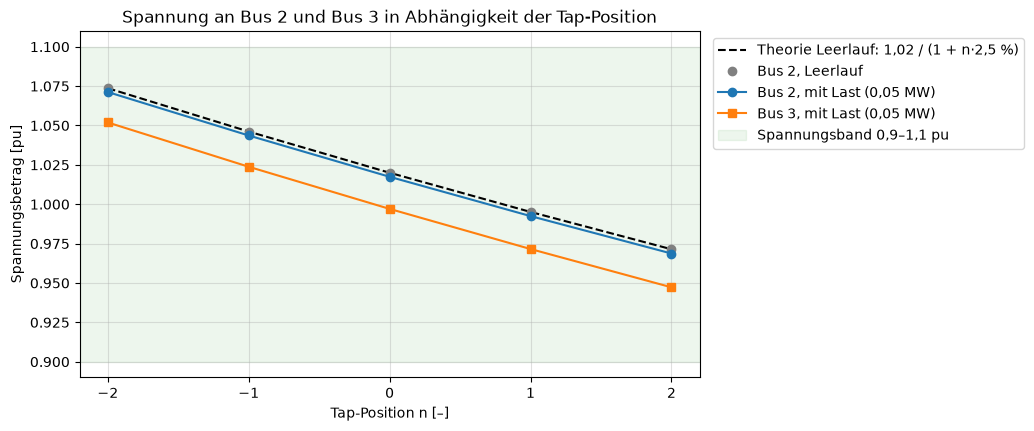

In [36]:
fig, ax = plt.subplots(figsize=(8, 4.5))
taps = df_tap["trafo.tap_pos"]
ax.plot(taps, df_tap_nl["Theorie [pu]"], "k--", label="Theorie Leerlauf: 1,02 / (1 + n·2,5 %)")
ax.plot(taps, df_tap_nl["vm Bus 2 Leerlauf [pu]"], "o", color="grey", label="Bus 2, Leerlauf")
ax.plot(taps, df_tap["vm Bus 2 [pu]"], "o-", label="Bus 2, mit Last (0,05 MW)")
ax.plot(taps, df_tap["vm Bus 3 [pu]"], "s-", label="Bus 3, mit Last (0,05 MW)")
ax.axhspan(0.9, 1.1, color="green", alpha=0.07, label="Spannungsband 0,9–1,1 pu")
ax.set_xticks(taps)
ax.set_xlabel("Tap-Position n [–]")
ax.set_ylabel("Spannungsbetrag [pu]")
ax.set_title("Spannung an Bus 2 und Bus 3 in Abhängigkeit der Tap-Position")
ax.grid(True, alpha=0.4)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

### Auswertung

Alle zehn Lastflüsse (mit Last und im Leerlauf) konvergieren.

**Richtung:** Eine höhere Tap-Position senkt die Spannung auf der Unterspannungsseite. Das entspricht der Theorie für einen Stufenschalter auf der OS-Seite: Mehr wirksame OS-Windungen vergrößern die Übersetzung. Bus 1 bleibt als Slack-Bus unverändert bei 1,02 pu.

**Größenordnung:**

| Tap | Theorie (Leerlauf) | Bus 2 Leerlauf | Bus 2 mit Last | Bus 3 mit Last |
|---|---|---|---|---|
| −2 | 1,0737 | 1,0737 | 1,0712 | 1,0519 |
| −1 | 1,0462 | 1,0461 | 1,0437 | 1,0238 |
| 0 | 1,0200 | 1,0200 | 1,0174 | 0,9970 |
| +1 | 0,9951 | 0,9951 | 0,9925 | 0,9716 |
| +2 | 0,9714 | 0,9714 | 0,9687 | 0,9473 |

- Im **Leerlauf** stimmt die Simulation bis auf 0,00003 pu mit u = 1,02 / (1 + n · 0,025) überein. Die kleine Restabweichung stammt vom Leerlaufstrom des Trafos (Magnetisierung, `i0_percent`). Eine Stufe verschiebt die Spannung um etwa 2,4–2,7 %. Der Wert ist nicht exakt symmetrisch, weil die Stufe im Nenner steht: 1/0,975 = 1,0256, aber 1/1,025 = 0,9756.
- **Mit Last** liegt Bus 2 um etwa 0,0026 pu unter dem Leerlaufwert (Spannungsfall über der Trafoimpedanz), Bus 3 zusätzlich um etwa 0,02 pu (Spannungsfall über dem Kabel). Diese Spannungsfälle werden vom Stufenschalter **nicht beeinflusst**: Er verschiebt das gesamte NS-Spannungsniveau parallel.
- Der Spannungsfall Bus 2 → 3 nimmt mit steigender Tap-Position leicht zu (0,0193 → 0,0214 pu), weil die Konstantleistungslast bei niedrigerer Spannung mehr Strom zieht (68,9 A → 76,6 A).

**Spannungsband:** Im aktuellen Betriebspunkt bleiben alle Stellungen im Band 0,9–1,1 pu. Der volle Regelbereich verschiebt Bus 3 zwischen 0,947 und 1,052 pu, also um insgesamt etwa 10 %. Ob das ausreicht, um die saisonalen Schwankungen durch Last und PV auszugleichen, wird in Aufgabe 4 und 5 untersucht.

## Aufgabe 3 – Saisonale Profile (Vorbereitung)

Beispielhafte Darstellung der eingelesenen Profile. Die Werte sind hier noch normiert auf 1 Mio. kWh Jahresverbrauch; über `annual_kwh` wird später auf die Haushalte des Ortsnetzes skaliert, über `unit="MW"` in die Einheit von pandapower umgerechnet.

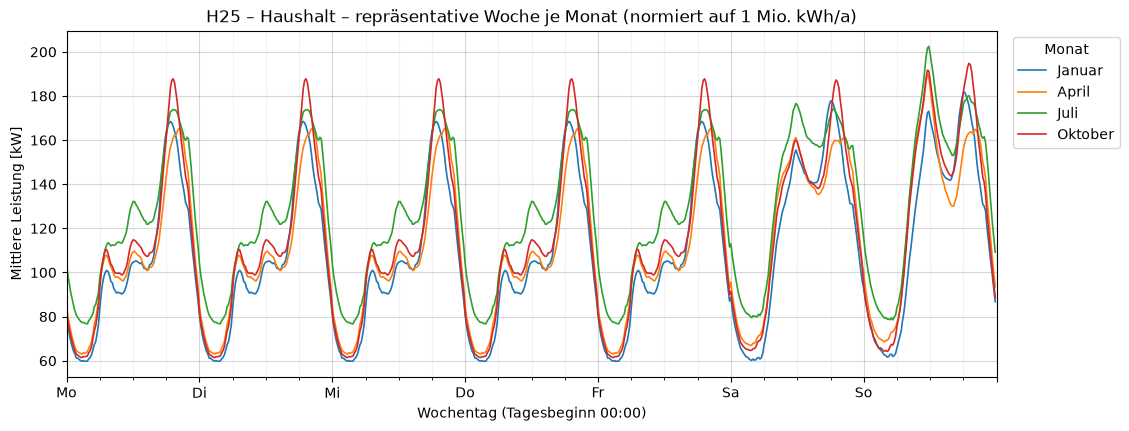

In [37]:
pr.plot_week(PROFILES, Lastprofil.HAUSHALT, months=[Month.JANUARY, Month.APRIL, Month.JULY, Month.OCTOBER])
plt.show()

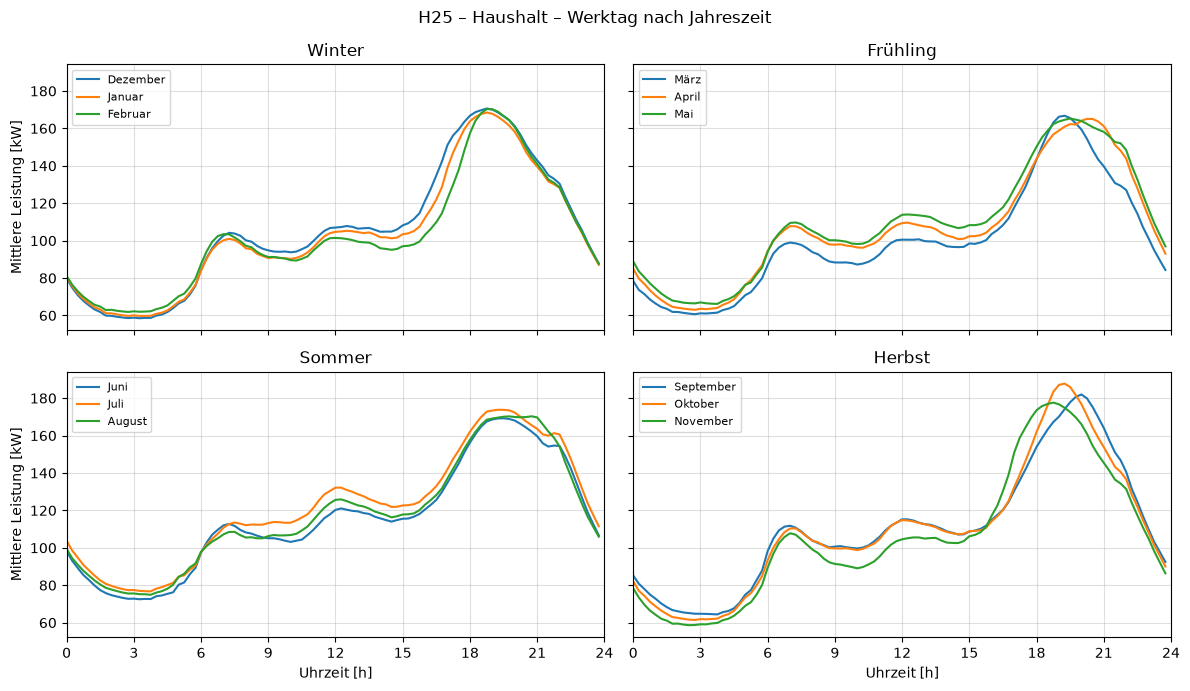

In [38]:
pr.plot_seasons(PROFILES, Lastprofil.HAUSHALT, daytype=DayType.WT)
plt.show()

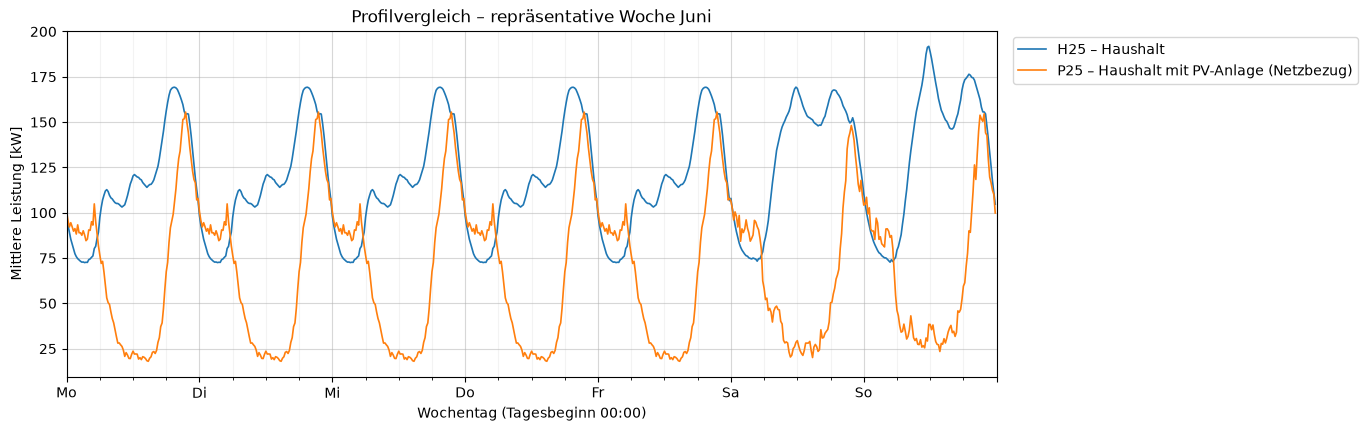

In [39]:
pr.plot_compare(PROFILES, [Lastprofil.HAUSHALT, Lastprofil.PV], Month.JUNE)
plt.show()

In [40]:
# Beispiel: repräsentative Juliwoche eines Haushalts mit 3.500 kWh/a in MW für pandapower
week_july = pr.build_week(PROFILES, Lastprofil.HAUSHALT, Month.JULY, annual_kwh=3500, unit="MW")
week_july.head()

2025-07-07 00:00:00    0.000364
2025-07-07 00:15:00    0.000345
2025-07-07 00:30:00    0.000331
2025-07-07 00:45:00    0.000318
2025-07-07 01:00:00    0.000308
Freq: 15min, Name: H25 – Haushalt [MW], dtype: float64